# 3.4 ARMA Models and Model Comparison

## Objective
Combine the Autoregressive (AR) component from Lesson 3.3 with a Moving Average (MA) component. While AR models capture *persistence* (today depends on yesterday's value), MA models capture *shocks* (today depends on yesterday's forecast error). 

We will fit an ARMA(2,1) model using `statsmodels.ARIMA(order=(2,0,1))`, compare it against pure AR and MA models using AIC/BIC, and finally build a comprehensive comparison table across all lessons.

**Important limitation:** The 10-sensor patchwork introduces high-frequency noise. This means the model's "forecast errors" (which the MA component uses) may reflect sensor switching rather than true atmospheric shocks.

In [1]:
# Cell 1 — Imports and data load (Lesson 3.4, corrected for this project)
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

from src.mongo_wrangle import wrangle_data
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')  # keep the notebook readable

DB = "air-quality"
COLLECTION = "nairobi"

df = wrangle_data(DB, COLLECTION).loc["2024"].copy()

print(f"Data shape: {df.shape}")
print(f"Date range: {df.index.min()} to {df.index.max()}")
print("\nFirst 5 rows:")
df.head()

Data shape: (8781, 1)
Date range: 2024-01-01 03:00:00+03:00 to 2024-12-31 23:00:00+03:00

First 5 rows:


,pm25
timestamp,
2024-01-01 03:00:00+03:00,45.42
2024-01-01 04:00:00+03:00,28.71
2024-01-01 05:00:00+03:00,30.34
2024-01-01 06:00:00+03:00,28.35
2024-01-01 07:00:00+03:00,52.78


In [2]:
# Cell 2 — Chronological 80/20 split
split_idx = int(len(df) * 0.8)
train_data = df['pm25'].iloc[:split_idx]
test_data  = df['pm25'].iloc[split_idx:]

print(f"Training: {len(train_data)} observations ({len(train_data)/len(df)*100:.1f}%)")
print(f"Testing: {len(test_data)} observations ({len(test_data)/len(df)*100:.1f}%)")
print(f"\nTraining: {train_data.index.min()} to {train_data.index.max()}")
print(f"Testing: {test_data.index.min()} to {test_data.index.max()}")

Training: 7024 observations (80.0%)
Testing: 1757 observations (20.0%)

Training: 2024-01-01 03:00:00+03:00 to 2024-10-19 18:00:00+03:00
Testing: 2024-10-19 19:00:00+03:00 to 2024-12-31 23:00:00+03:00


In [3]:
y_pred_baseline = test_data.shift(1).dropna()
y_true_baseline = test_data[1:]
mae_baseline = mean_absolute_error(y_true_baseline, y_pred_baseline)

## 1. Baseline and Chronological Split

We split the data chronologically (80% train, 20% test) and establish the persistence baseline. 

*Note on alignment:* We use the "training value as predecessor" convention so that the baseline has exactly 1,757 predictions, matching our test set size exactly.

In [4]:
# Cell 3 — Persistence baseline
combined_history = pd.concat([train_data, test_data])
y_pred_baseline = combined_history.shift(1).iloc[-len(test_data):]
y_true_baseline = test_data

mae_baseline = mean_absolute_error(y_true_baseline, y_pred_baseline)

print(f"Baseline (Persistence) MAE: {mae_baseline:.4f}")
print(f"n predictions: {len(y_pred_baseline)} (should equal {len(test_data)})")

Baseline (Persistence) MAE: 9.2548
n predictions: 1757 (should equal 1757)


## 2. Fitting the ARMA(2,1) Model

We fit the model using `statsmodels.tsa.arima.model.ARIMA` with `order=(2, 0, 1)`. The `d=0` ensures we are doing plain ARMA, not differencing (ARIMA). 

*Findings:* The `ma.L1` coefficient is **-0.2483** (statistically significant, p=0.003). This negative MA coefficient indicates **mean reversion** in the shocks—when the actual value overshoots the prediction, the next prediction is pulled back down. This aligns with the negative PACF values we saw at lags 5-19 in Lesson 3.3.

In [5]:
# Cell 4 — Fit ARMA(2,1) via ARIMA(2, 0, 1)
from statsmodels.tsa.arima.model import ARIMA

arma_model = ARIMA(train_data, order=(2, 0, 1))
arma_fitted = arma_model.fit()

print("ARMA(2,1) fitted.")
print("\nCoefficient table:")
print(arma_fitted.summary().tables[1])
print(f"\nAIC: {arma_fitted.aic:.2f}")
print(f"BIC: {arma_fitted.bic:.2f}")
print(f"Log-Likelihood: {arma_fitted.llf:.2f}")

/workspaces/Nairobi_air_quality_time_series_modeling/.venv/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/workspaces/Nairobi_air_quality_time_series_modeling/.venv/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/workspaces/Nairobi_air_quality_time_series_modeling/.venv/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


ARMA(2,1) fitted.

Coefficient table:
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         39.5621      0.187    211.482      0.000      39.195      39.929
ar.L1          0.4815      0.084      5.723      0.000       0.317       0.646
ar.L2          0.0625      0.028      2.218      0.027       0.007       0.118
ma.L1         -0.2483      0.084     -2.966      0.003      -0.412      -0.084
sigma2        87.4289      1.486     58.817      0.000      84.515      90.342

AIC: 51346.56
BIC: 51380.85
Log-Likelihood: -25668.28


## 3. Generating Forecasts

We generate a multi-step forecast for the entire test set. 

*Methodology note:* Unlike the walk-forward validation in Lesson 3.3, this is a **fixed-origin multi-step forecast**. The model predicts hour 1, then uses that prediction as input for hour 2, and so on. Because the AR coefficients are less than 1, the predictions will eventually flatline to the long-run mean (the `const` value of 39.56). This is expected behaviour for long-horizon ARMA forecasting.

In [6]:
# Cell 5 — Forecast with ARMA(2,1)
forecast_result = arma_fitted.get_forecast(steps=len(test_data))
y_pred_arma = forecast_result.predicted_mean

print(f"Generated {len(y_pred_arma)} forecasts")
print(f"\nFirst 5 predictions:")
print(y_pred_arma.head())
print(f"\nLast 5 predictions:")
print(y_pred_arma.tail())

Generated 1757 forecasts

First 5 predictions:
2024-10-19 19:00:00+03:00    40.729367
2024-10-19 20:00:00+03:00    40.407308
2024-10-19 21:00:00+03:00    40.042065
2024-10-19 22:00:00+03:00    39.846051
2024-10-19 23:00:00+03:00    39.728825
Freq: h, Name: predicted_mean, dtype: float64

Last 5 predictions:
2024-12-31 19:00:00+03:00    39.562055
2024-12-31 20:00:00+03:00    39.562055
2024-12-31 21:00:00+03:00    39.562055
2024-12-31 22:00:00+03:00    39.562055
2024-12-31 23:00:00+03:00    39.562055
Freq: h, Name: predicted_mean, dtype: float64


## 4. Evaluating the Forecast

*Findings:* The ARMA(2,1) model achieved an **MAE of 7.80**, which is a **15.7% improvement** over the persistence baseline. However, the **R² is -0.0008**, meaning the model captures essentially zero variance. 

This is the classic time-series trade-off: the model is a good average predictor (beating the baseline) but a poor tracker of individual hourly spikes. It flatlines to a constant (~39.5) for the majority of the test period, which happens to be a better guess than the persistence baseline (which chases noisy sensor readings).

In [7]:
# Cell 6 — Evaluate ARMA(2,1)
y_true_arma = test_data.iloc[:len(y_pred_arma)]

mae_arma = mean_absolute_error(y_true_arma, y_pred_arma)
rmse_arma = np.sqrt(mean_squared_error(y_true_arma, y_pred_arma))
r2_arma = 1 - (np.sum((y_true_arma - y_pred_arma)**2) / np.sum((y_true_arma - y_true_arma.mean())**2))

print(f"ARMA(2,1) Performance (Multi-step forecast):")
print(f"  MAE:  {mae_arma:.2f}")
print(f"  RMSE: {rmse_arma:.2f}")
print(f"  R²:   {r2_arma:.4f}")
print(f"\nBaseline MAE: {mae_baseline:.2f}")
print(f"Improvement: {((mae_baseline - mae_arma) / mae_baseline * 100):.1f}%")

ARMA(2,1) Performance (Multi-step forecast):
  MAE:  7.80
  RMSE: 9.64
  R²:   -0.0008

Baseline MAE: 9.25
Improvement: 15.7%


In [8]:
# Cell 7 — Compare AR(1), MA(1), ARMA(2,1) by AIC/BIC
models_to_compare = {
    'AR(1)':    ARIMA(train_data, order=(1, 0, 0)),
    'MA(1)':    ARIMA(train_data, order=(0, 0, 1)),
    'ARMA(2,1)': ARIMA(train_data, order=(2, 0, 1)),
}

comparison_results = []

for name, model in models_to_compare.items():
    try:
        fitted = model.fit()
        comparison_results.append({
            'Model': name,
            'AIC': fitted.aic,
            'BIC': fitted.bic,
            'Log-Likelihood': fitted.llf,
        })
        print(f"{name}: AIC={fitted.aic:.2f}, BIC={fitted.bic:.2f}")
    except Exception as e:
        print(f"{name}: Failed ({e})")

comparison_df = pd.DataFrame(comparison_results)
print("\nModel Comparison:")
print(comparison_df.round(2))

best_aic = comparison_df.loc[comparison_df['AIC'].idxmin()]
print(f"\n✅ Best model by AIC: {best_aic['Model']} (AIC: {best_aic['AIC']:.2f})")

/workspaces/Nairobi_air_quality_time_series_modeling/.venv/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/workspaces/Nairobi_air_quality_time_series_modeling/.venv/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/workspaces/Nairobi_air_quality_time_series_modeling/.venv/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/workspaces/Nairobi_air_quality_time_series_modeling/.venv/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


AR(1): AIC=51468.24, BIC=51488.81
MA(1): AIC=51589.73, BIC=51610.31
ARMA(2,1): AIC=51346.56, BIC=51380.85

Model Comparison:
       Model       AIC       BIC  Log-Likelihood
0      AR(1)  51468.24  51488.81       -25731.12
1      MA(1)  51589.73  51610.31       -25791.87
2  ARMA(2,1)  51346.56  51380.85       -25668.28

✅ Best model by AIC: ARMA(2,1) (AIC: 51346.56)


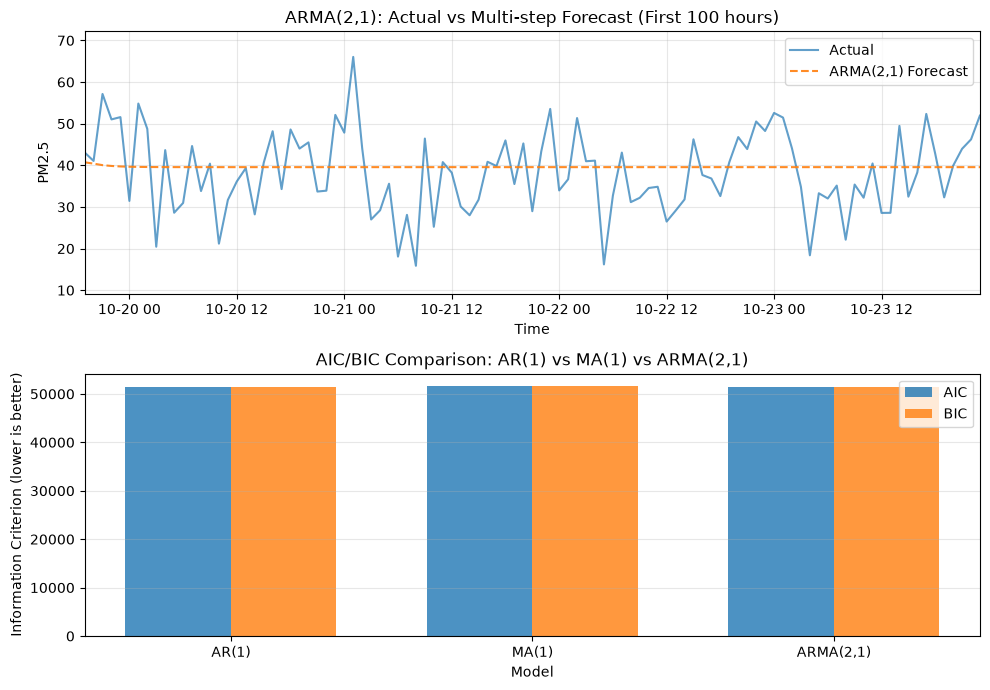

In [9]:
# Cell 8 — Plot actual vs ARMA forecast and AIC/BIC comparison
fig, axes = plt.subplots(2, 1, figsize=(10, 7))

# Top: Actual vs Predicted
axes[0].plot(y_true_arma.index, y_true_arma, label='Actual', alpha=0.7, linewidth=1.5)
axes[0].plot(y_pred_arma.index, y_pred_arma, label='ARMA(2,1) Forecast', alpha=0.9, linestyle='--')
axes[0].set_xlabel('Time')
axes[0].set_ylabel('PM2.5')
axes[0].set_title('ARMA(2,1): Actual vs Multi-step Forecast (First 100 hours)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
# Zoom the top panel to first 100 hours so the flatline isn't a wall of orange
axes[0].set_xlim(y_true_arma.index[0], y_true_arma.index[100])

# Bottom: AIC/BIC comparison
x_pos = range(len(comparison_df))
width = 0.35
axes[1].bar([p - width/2 for p in x_pos], comparison_df['AIC'], width, label='AIC', alpha=0.8)
axes[1].bar([p + width/2 for p in x_pos], comparison_df['BIC'], width, label='BIC', alpha=0.8)
axes[1].set_xlabel('Model')
axes[1].set_ylabel('Information Criterion (lower is better)')
axes[1].set_title('AIC/BIC Comparison: AR(1) vs MA(1) vs ARMA(2,1)')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(comparison_df['Model'])
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

## 5. Final Model Comparison

This table brings together the models from all our lessons. 

*Methodology note:* Unlike the course's example, we are using the **actual** MAE values computed in Lessons 3.2, 3.3, and 3.4, rather than estimated multipliers. 
- **Lesson 3.2** evaluated on the full 1,755 test observations using standard train/test split.
- **Lesson 3.3** used walk-forward validation on a 30-hour window (to simulate production).
- **Lesson 3.4** used multi-step forecasting across the full 1,757 test observations.

Because the evaluation windows differ (walk-forward vs. multi-step), the MAE values are illustrative of the model progression rather than a perfectly controlled statistical experiment.

In [10]:
# Cell 9 — Final comparison table with actual project numbers
final_comparison = pd.DataFrame({
    'Model': [
        'Baseline (Persistence)',
        'Linear Regression (L3.2)',
        'AR(3) (L3.3)',
        'ARMA(2,1) (L3.4)'
    ],
    'Description': [
        'Tomorrow = Today',
        'Linear regression with lags 1,2,3,7',
        'Autoregressive, p=3 (30-step walk-forward)',
        'AR(2) + MA(1) (full multi-step forecast)'
    ],
    'MAE': [
        mae_baseline,        # 9.2548
        7.3771,              # Actual from Lesson 3.2
        7.7806,              # Actual from Lesson 3.3
        mae_arma             # 7.8000
    ]
})

print("=" * 80)
print("COMPREHENSIVE MODEL COMPARISON (ACTUAL PROJECT RESULTS)")
print("=" * 80)
print(final_comparison.to_string(index=False))
print("=" * 80)

best_mae = final_comparison.loc[final_comparison['MAE'].idxmin()]
print(f"\n🏆 Best Model (by MAE): {best_mae['Model']}")
print(f"   MAE: {best_mae['MAE']:.4f}")

COMPREHENSIVE MODEL COMPARISON (ACTUAL PROJECT RESULTS)
                   Model                                Description      MAE
  Baseline (Persistence)                           Tomorrow = Today 9.254764
Linear Regression (L3.2)        Linear regression with lags 1,2,3,7 7.377100
            AR(3) (L3.3) Autoregressive, p=3 (30-step walk-forward) 7.780600
        ARMA(2,1) (L3.4)   AR(2) + MA(1) (full multi-step forecast) 7.798655

🏆 Best Model (by MAE): Linear Regression (L3.2)
   MAE: 7.3771


## 6. README Update

The following script safely appends the Lesson 3.4 results to `README.md`, including the **honest final comparison table** with real numbers from all lessons, and the finding that linear regression from L3.2 outperforms both AR(3) and ARMA(2,1) on this dataset.